In this data visualisation practice sheet i use all libraries like pandas,numpy,matplotlib,aggregation,wrangling,visualisation,dataframe,etc....
created by-Ram Sharma

Q-1

   customer_state  total_item_price  distinct_order_count
25             SP         5427808.0                 16188
18             RJ         1669256.0                  5079
10             MG         1508676.0                  4378
22             RS          829301.0                  2184
17             PR          711489.0                  1905
23             SC          464679.0                  1406
4              BA          442008.0                  1275
6              DF          288017.0                   844
8              GO          276987.0                   740
7              ES          263805.0                   752


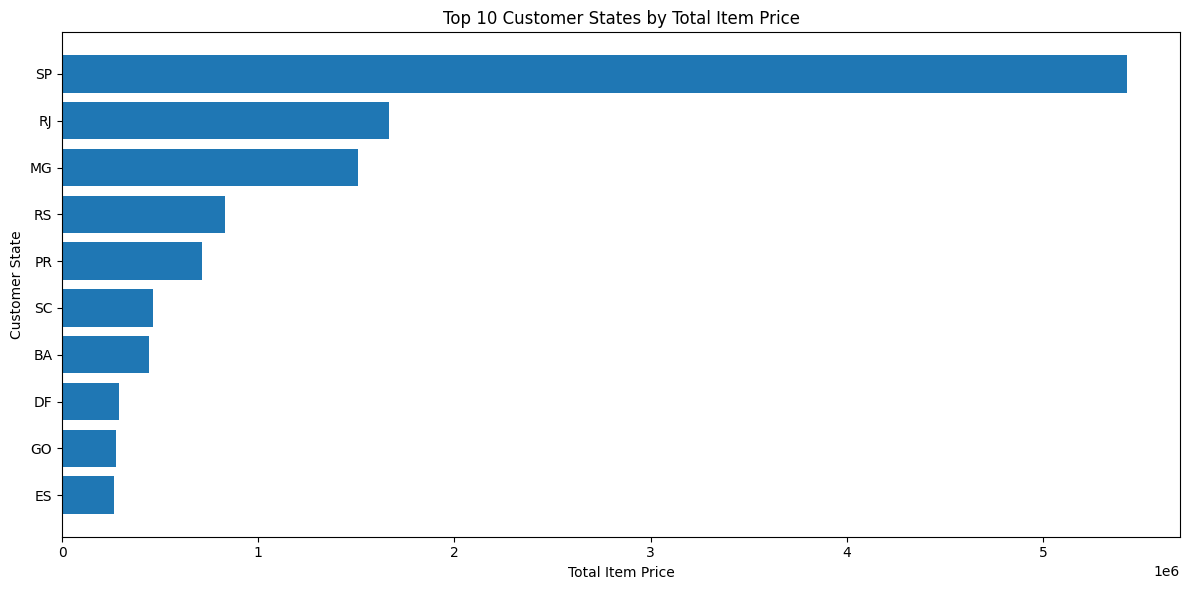

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

customers = pd.read_csv('customers.csv')
order_items = pd.read_csv('order_items.csv')
orders = pd.read_csv('orders.csv')

df = pd.merge(order_items, orders, on='order_id')
df = pd.merge(df, customers, on='customer_id')

df = df.dropna(subset=['customer_state', 'price', 'order_id'])

df['price'] = pd.to_numeric(df['price'], errors='coerce')
df = df.dropna(subset=['price'])

result = df.groupby('customer_state').agg(
    total_item_price=('price', 'sum'),
    distinct_order_count=('order_id', 'nunique')
).reset_index()

top_10 = result.sort_values(
    by='total_item_price',
    ascending=False
).head(10)

print(top_10)

plt.figure(figsize=(12, 6))
plt.barh(top_10['customer_state'], top_10['total_item_price'])

plt.xlabel('Total Item Price')
plt.ylabel('Customer State')
plt.title('Top 10 Customer States by Total Item Price')

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

q-2

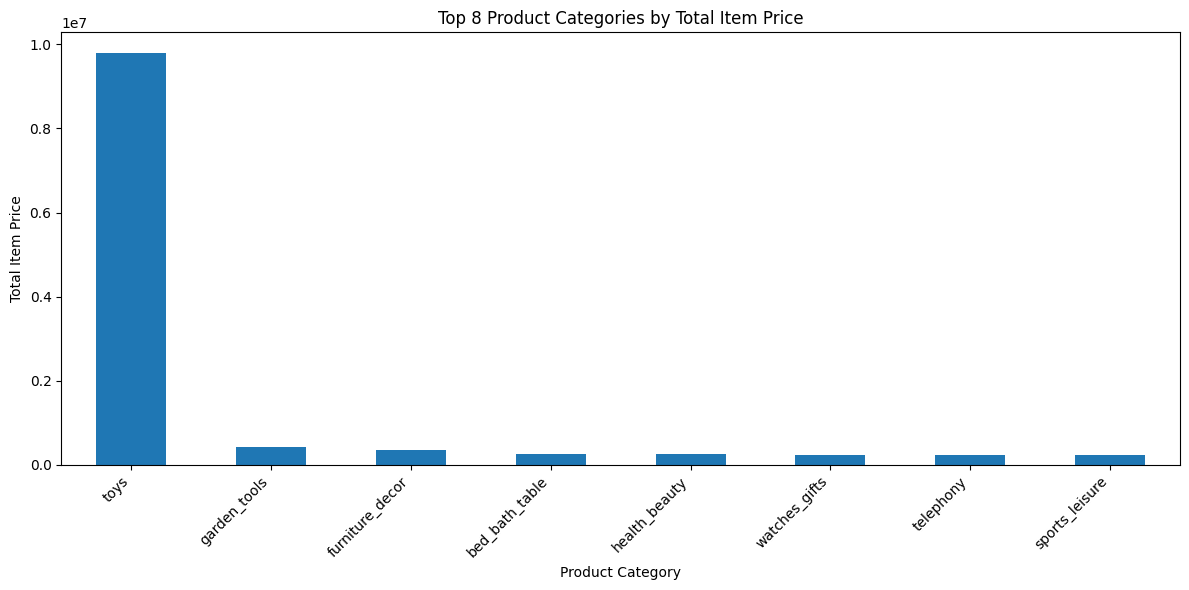

In [24]:
df = pd.merge(order_items, products, on='product_id')

df['product_category_name'] = df['product_category_name'].fillna('Unknown')

result = df.groupby('product_category_name')['price'].sum().reset_index()

top_8 = result.sort_values(by='price', ascending=False).head(8)

top_8 = top_8.set_index('product_category_name')

top_8.plot(kind='bar', figsize=(12, 6), legend=False)

plt.xlabel('Product Category')
plt.ylabel('Total Item Price')
plt.title('Top 8 Product Categories by Total Item Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

q-3

Observation Period:
2016-10 to 2018-09


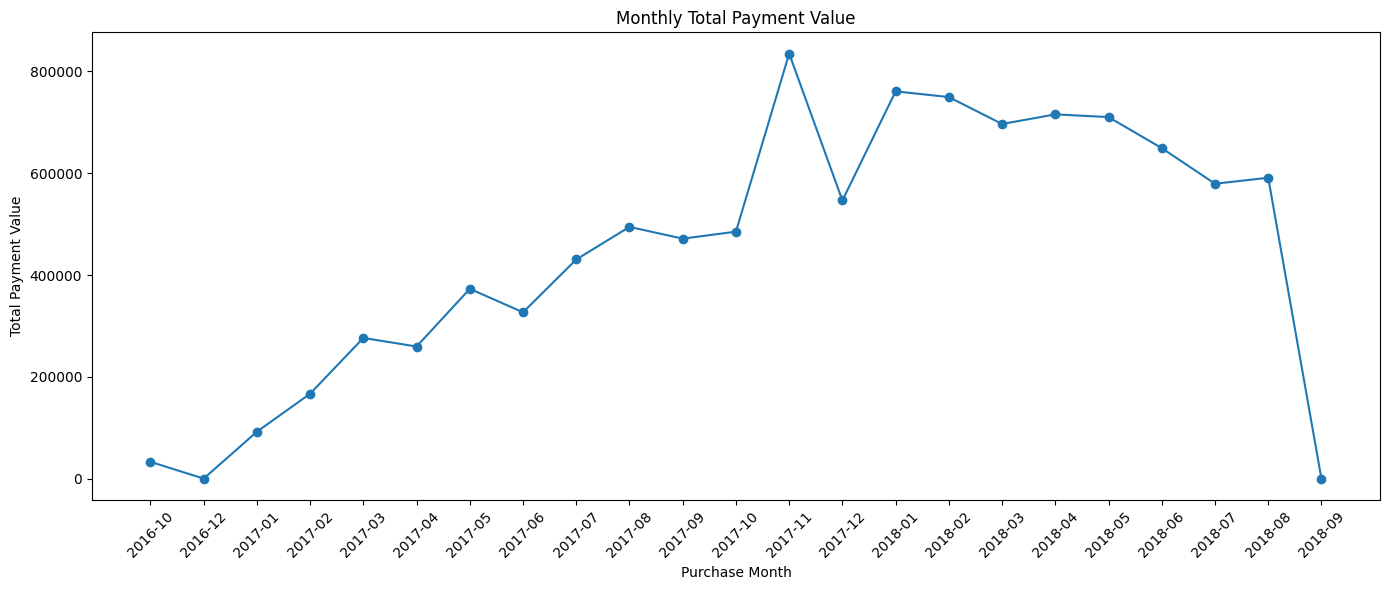

In [25]:
df = pd.merge(payments, orders, on='order_id')

df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp']
)

df = df.dropna(subset=['order_purchase_timestamp'])

df['month'] = df['order_purchase_timestamp'].dt.to_period('M')

monthly_data = df.groupby('month')['payment_value'].sum().reset_index()

monthly_data = monthly_data.sort_values('month')

print("Observation Period:")
print(monthly_data['month'].iloc[0], "to", monthly_data['month'].iloc[-1])

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data['month'].astype(str),
    monthly_data['payment_value'],
    marker='o'
)

plt.xlabel('Purchase Month')
plt.ylabel('Total Payment Value')
plt.title('Monthly Total Payment Value')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

q-4

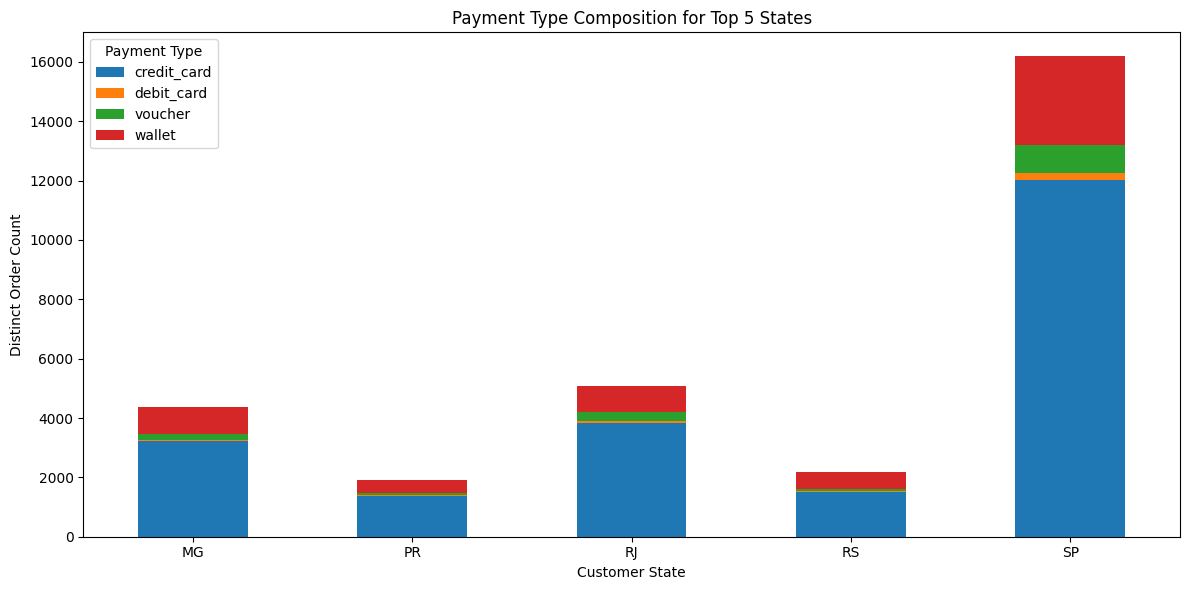

In [26]:
df = pd.merge(orders, customers, on='customer_id')
df = pd.merge(df, payments, on='order_id')

state_orders = df.groupby('customer_state')['order_id'].nunique()

top_5_states = state_orders.sort_values(ascending=False).head(5).index

df = df[df['customer_state'].isin(top_5_states)]

result = df.groupby(['customer_state', 'payment_type'])['order_id'].nunique().unstack(fill_value=0)

result.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.xlabel('Customer State')
plt.ylabel('Distinct Order Count')
plt.title('Payment Type Composition for Top 5 States')
plt.xticks(rotation=0)
plt.legend(title='Payment Type')
plt.tight_layout()
plt.show()

Q-5


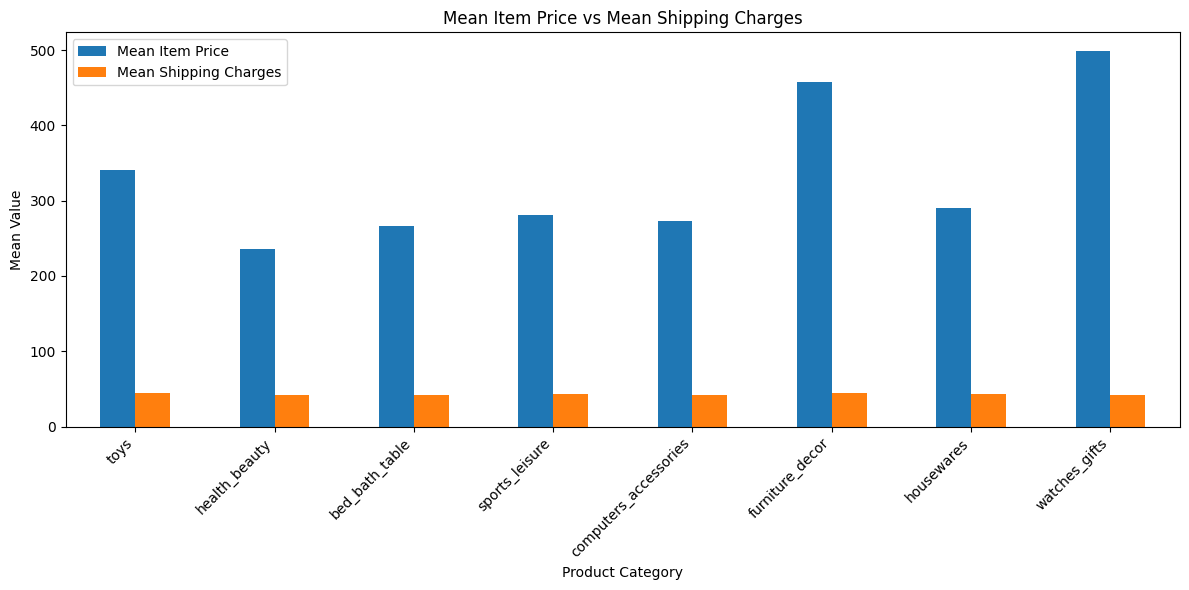

In [28]:
df = pd.merge(order_items, products, on='product_id')

df['product_category_name'] = df['product_category_name'].fillna('Unknown')

result = df.groupby('product_category_name').agg(
    distinct_orders=('order_id', 'nunique'),
    mean_item_price=('price', 'mean'),
    mean_shipping_charges=('shipping_charges', 'mean')
).reset_index()

top_8 = result.sort_values(
    by='distinct_orders',
    ascending=False
).head(8)

top_8 = top_8.set_index('product_category_name')

top_8[['mean_item_price', 'mean_shipping_charges']].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.xlabel('Product Category')
plt.ylabel('Mean Value')
plt.title('Mean Item Price vs Mean Shipping Charges')
plt.xticks(rotation=45, ha='right')
plt.legend(['Mean Item Price', 'Mean Shipping Charges'])
plt.tight_layout()
plt.show()

In [ ]:
Q-6

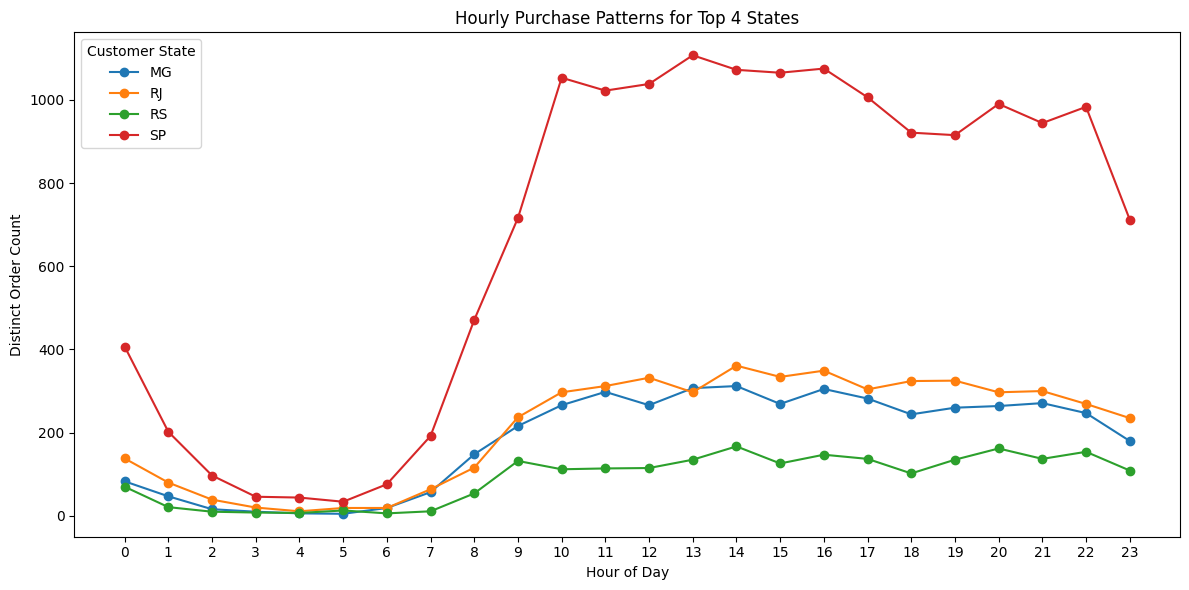

In [29]:
import seaborn as sns

df = pd.merge(orders, customers, on='customer_id')

df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp']
)

df['hour'] = df['order_purchase_timestamp'].dt.hour

top_4 = df.groupby('customer_state')['order_id'].nunique().nlargest(4).index

df = df[df['customer_state'].isin(top_4)]

result = df.groupby(['hour', 'customer_state'])['order_id'].nunique().unstack(fill_value=0)

result = result.reindex(range(24), fill_value=0)

result.plot(figsize=(12, 6), marker='o')

plt.xlabel('Hour of Day')
plt.ylabel('Distinct Order Count')
plt.title('Hourly Purchase Patterns for Top 4 States')
plt.xticks(range(24))
plt.legend(title='Customer State')
plt.tight_layout()
plt.show()

Q-7

              price
count  38279.000000
mean     342.533295
std      560.289323
min        1.000000
25%       60.000000
50%      137.000000
75%      399.000000
max     6729.000000


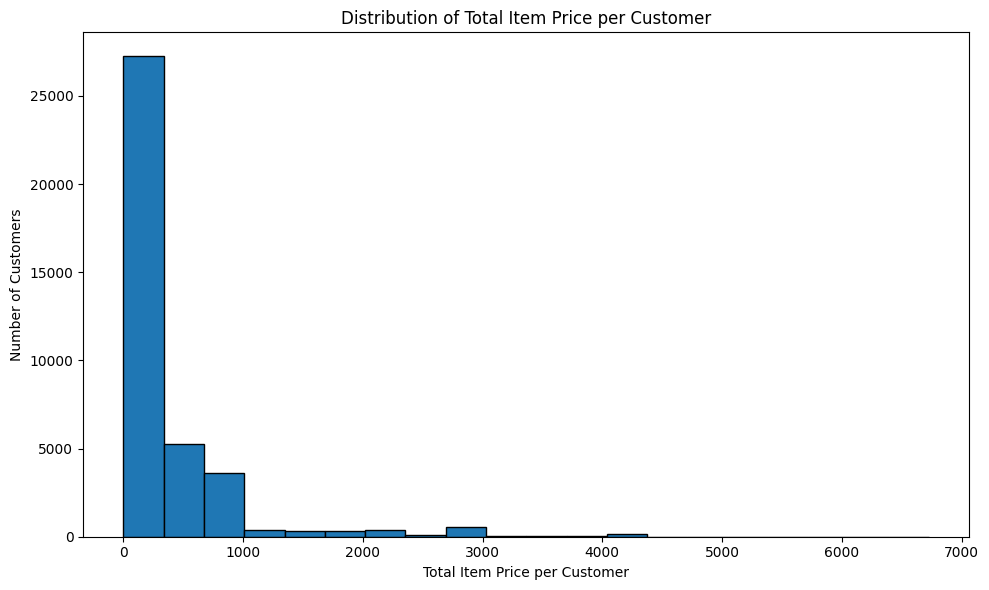

Skewness: 3.757578022937641


In [30]:
df = pd.merge(order_items, orders, on='order_id')

customer_data = df.groupby('customer_id')['price'].sum().reset_index()

customer_data = customer_data.dropna(subset=['price'])

print(customer_data.describe())

plt.figure(figsize=(10, 6))

plt.hist(customer_data['price'], bins=20, edgecolor='black')

plt.xlabel('Total Item Price per Customer')
plt.ylabel('Number of Customers')
plt.title('Distribution of Total Item Price per Customer')

plt.tight_layout()
plt.show()

print("Skewness:", customer_data['price'].skew())

Q-8

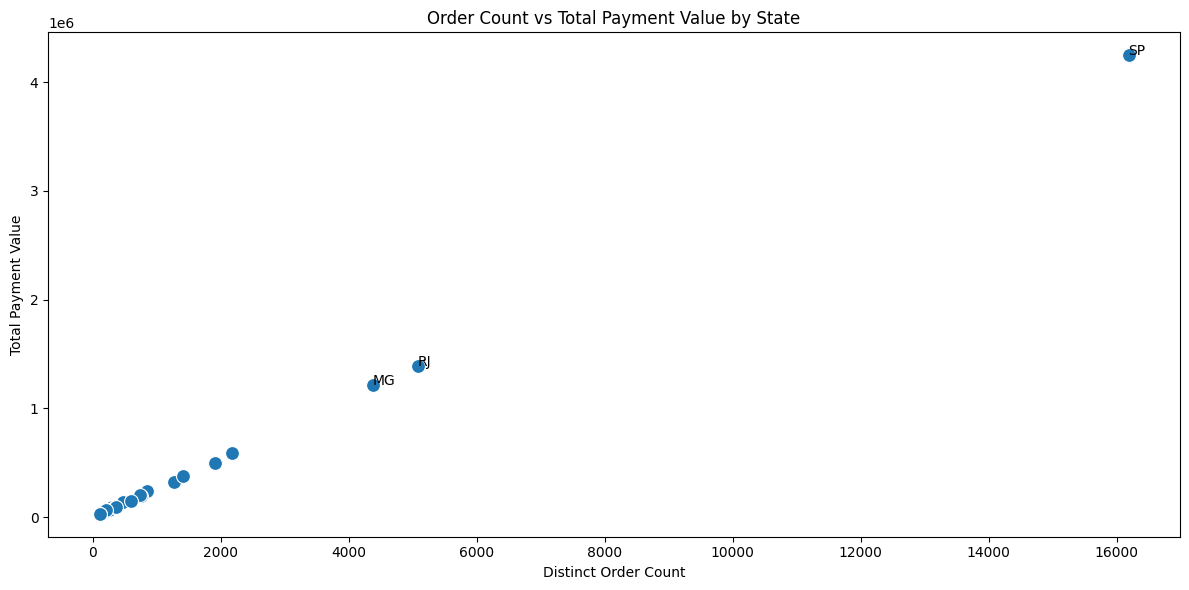

In [31]:
import seaborn as sns

df = pd.merge(orders, customers, on='customer_id')
df = pd.merge(df, payments, on='order_id')

result = df.groupby('customer_state').agg(
    order_count=('order_id', 'nunique'),
    total_payment_value=('payment_value', 'sum')
).reset_index()

result = result[result['order_count'] >= 100]

top_3 = result.nlargest(3, 'total_payment_value')

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=result,
    x='order_count',
    y='total_payment_value',
    s=100
)

for i in range(len(top_3)):
    plt.annotate(
        top_3.iloc[i]['customer_state'],
        (top_3.iloc[i]['order_count'], top_3.iloc[i]['total_payment_value'])
    )

plt.xlabel('Distinct Order Count')
plt.ylabel('Total Payment Value')
plt.title('Order Count vs Total Payment Value by State')

plt.tight_layout()
plt.show()

Q-9

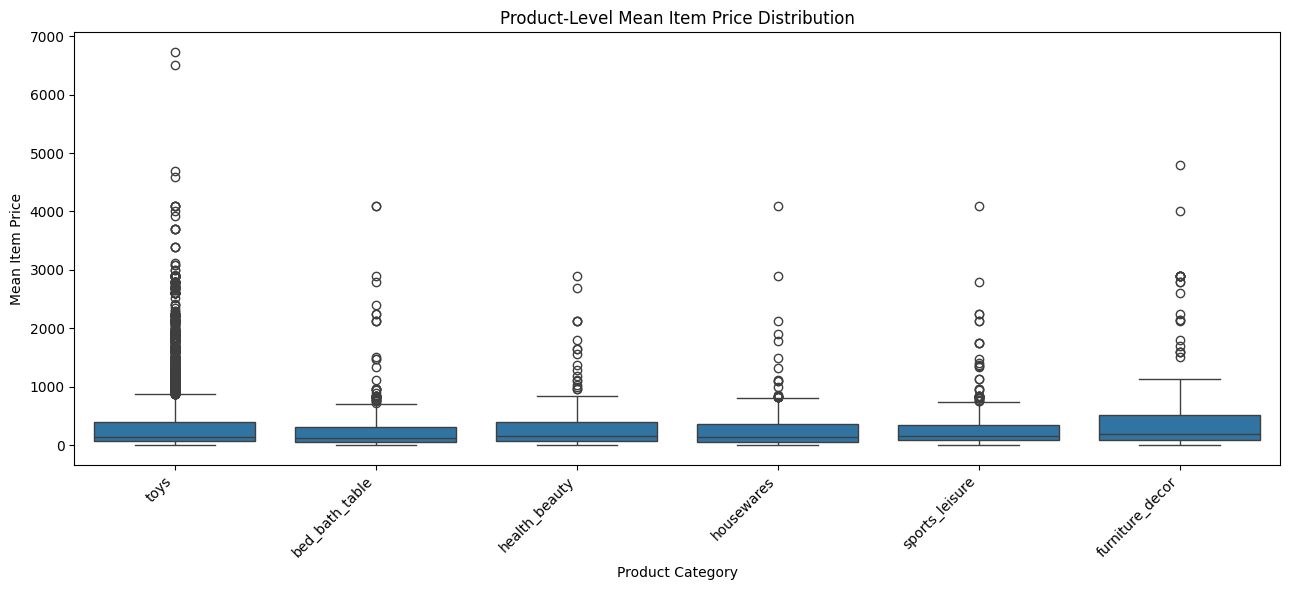

In [32]:
import seaborn as sns

df = pd.merge(order_items, products, on='product_id')

df['product_category_name'] = df['product_category_name'].fillna('Unknown')

product_data = df.groupby(
    ['product_id', 'product_category_name']
)['price'].mean().reset_index()

top_6 = product_data.groupby('product_category_name')['product_id'].nunique().nlargest(6).index

product_data = product_data[
    product_data['product_category_name'].isin(top_6)
]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=product_data,
    x='product_category_name',
    y='price'
)

plt.xlabel('Product Category')
plt.ylabel('Mean Item Price')
plt.title('Product-Level Mean Item Price Distribution')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Q-10

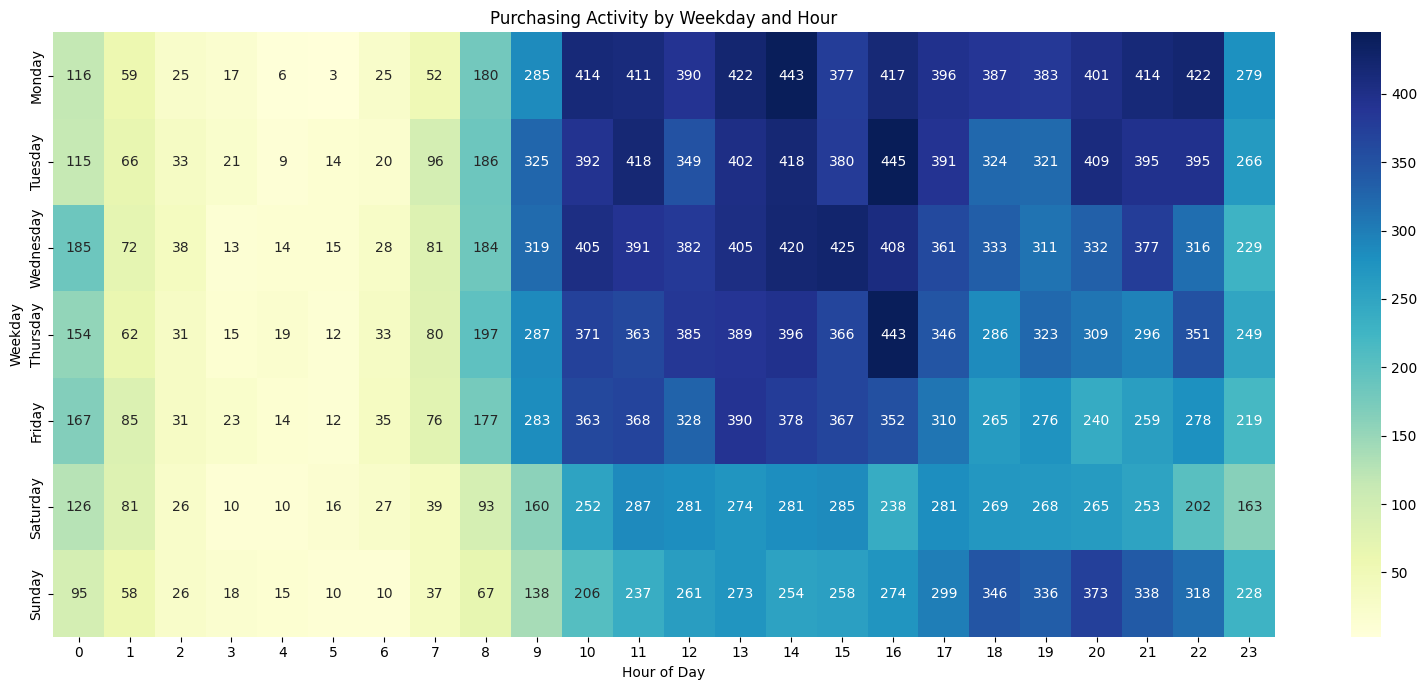

In [33]:
import seaborn as sns

df = orders.copy()

df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp']
)

df = df.dropna(subset=['order_purchase_timestamp'])

df['weekday'] = df['order_purchase_timestamp'].dt.day_name()
df['hour'] = df['order_purchase_timestamp'].dt.hour

days = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

result = df.pivot_table(
    index='weekday',
    columns='hour',
    values='order_id',
    aggfunc='nunique',
    fill_value=0
)

result = result.reindex(index=days, columns=range(24), fill_value=0)

plt.figure(figsize=(16, 7))

sns.heatmap(
    result,
    annot=True,
    fmt='g',
    cmap='YlGnBu'
)

plt.xlabel('Hour of Day')
plt.ylabel('Weekday')
plt.title('Purchasing Activity by Weekday and Hour')

plt.tight_layout()
plt.show()

Q-11

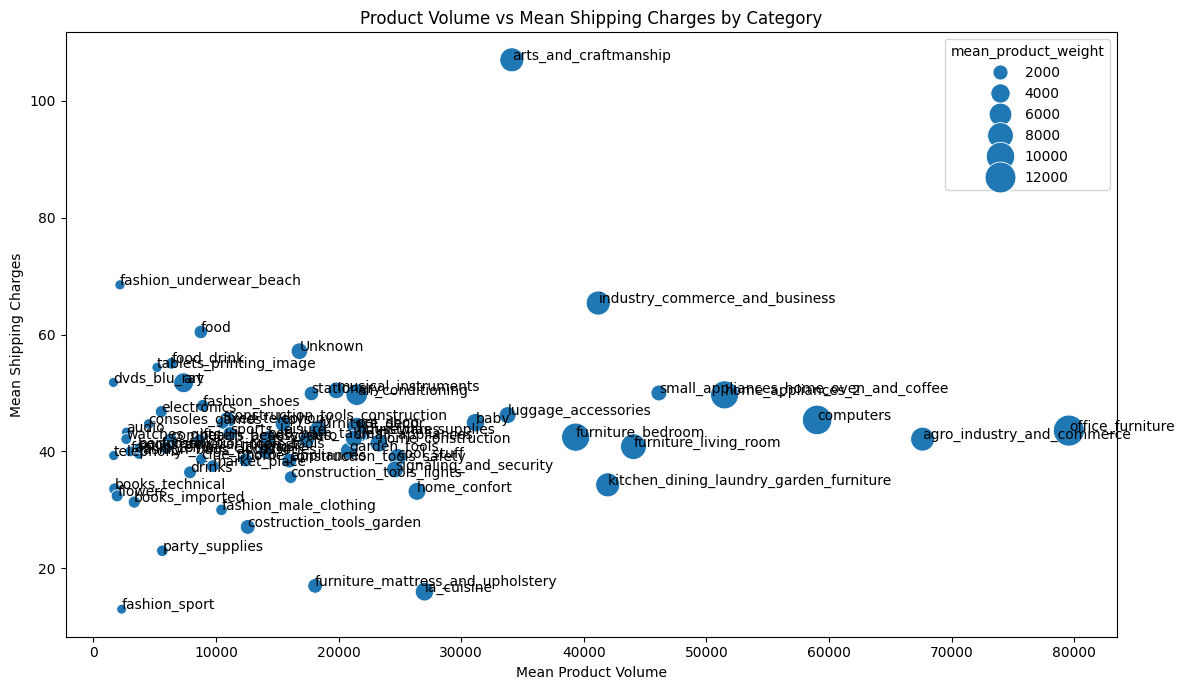

In [34]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.merge(order_items, products, on='product_id')

df['product_category_name'] = df['product_category_name'].fillna('Unknown')

df['product_volume'] = (
    df['product_length_cm'] *
    df['product_height_cm'] *
    df['product_width_cm']
)

df = df.dropna(subset=[
    'product_weight_g',
    'product_volume',
    'shipping_charges'
])

df = df[
    (df['product_weight_g'] > 0) &
    (df['product_volume'] > 0)
]

result = df.groupby('product_category_name').agg(
    mean_product_volume=('product_volume', 'mean'),
    mean_shipping_charges=('shipping_charges', 'mean'),
    mean_product_weight=('product_weight_g', 'mean')
).reset_index()

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=result,
    x='mean_product_volume',
    y='mean_shipping_charges',
    size='mean_product_weight',
    sizes=(50, 500),
    legend=True
)

for i in range(len(result)):
    plt.annotate(
        result.iloc[i]['product_category_name'],
        (result.iloc[i]['mean_product_volume'],
         result.iloc[i]['mean_shipping_charges'])
    )

plt.xlabel('Mean Product Volume')
plt.ylabel('Mean Shipping Charges')
plt.title('Product Volume vs Mean Shipping Charges by Category')
plt.tight_layout()
plt.show()

Q-12

Available Observation Periods:
2018 2018-01-01 02:48:41 to 2018-09-03 09:06:57
2017 2017-01-05 12:01:20 to 2017-12-31 21:10:02


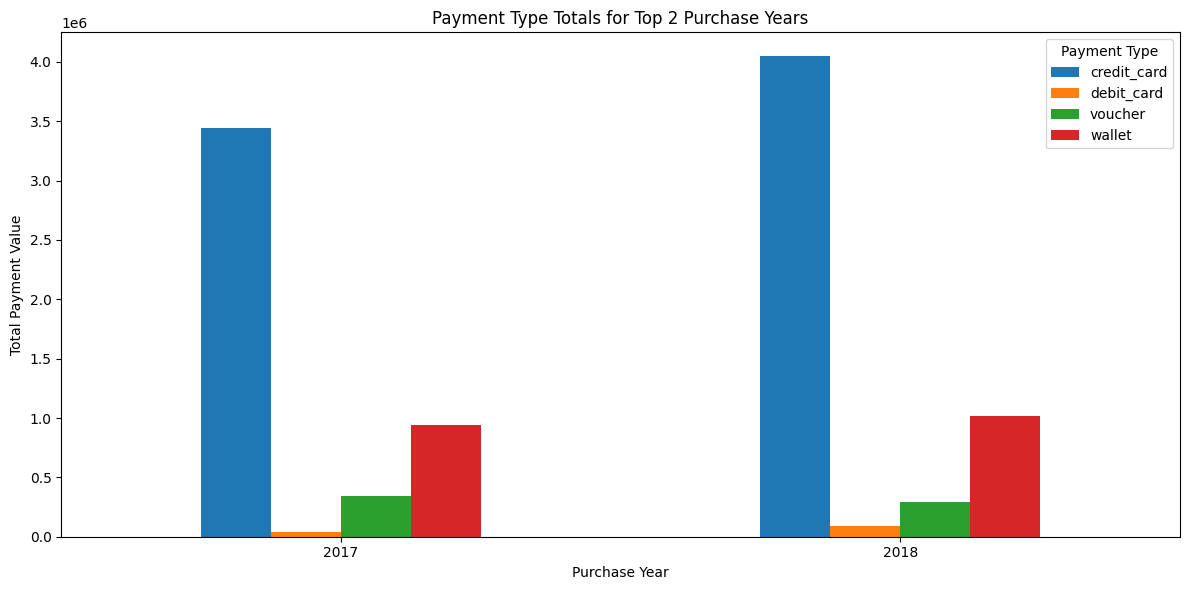

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.merge(payments, orders, on='order_id')

df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp']
)

df = df.dropna(subset=['order_purchase_timestamp'])

df['year'] = df['order_purchase_timestamp'].dt.year

year_totals = df.groupby('year')['payment_value'].sum()

top_2_years = year_totals.nlargest(2).index

df = df[df['year'].isin(top_2_years)]

result = df.groupby(['year', 'payment_type'])['payment_value'].sum().unstack(fill_value=0)

print("Available Observation Periods:")

for year in top_2_years:
    year_data = df[df['year'] == year]
    print(
        year,
        year_data['order_purchase_timestamp'].min(),
        "to",
        year_data['order_purchase_timestamp'].max()
    )

result.plot(kind='bar', figsize=(12, 6))

plt.xlabel('Purchase Year')
plt.ylabel('Total Payment Value')
plt.title('Payment Type Totals for Top 2 Purchase Years')
plt.xticks(rotation=0)
plt.legend(title='Payment Type')
plt.tight_layout()
plt.show()

Q-13

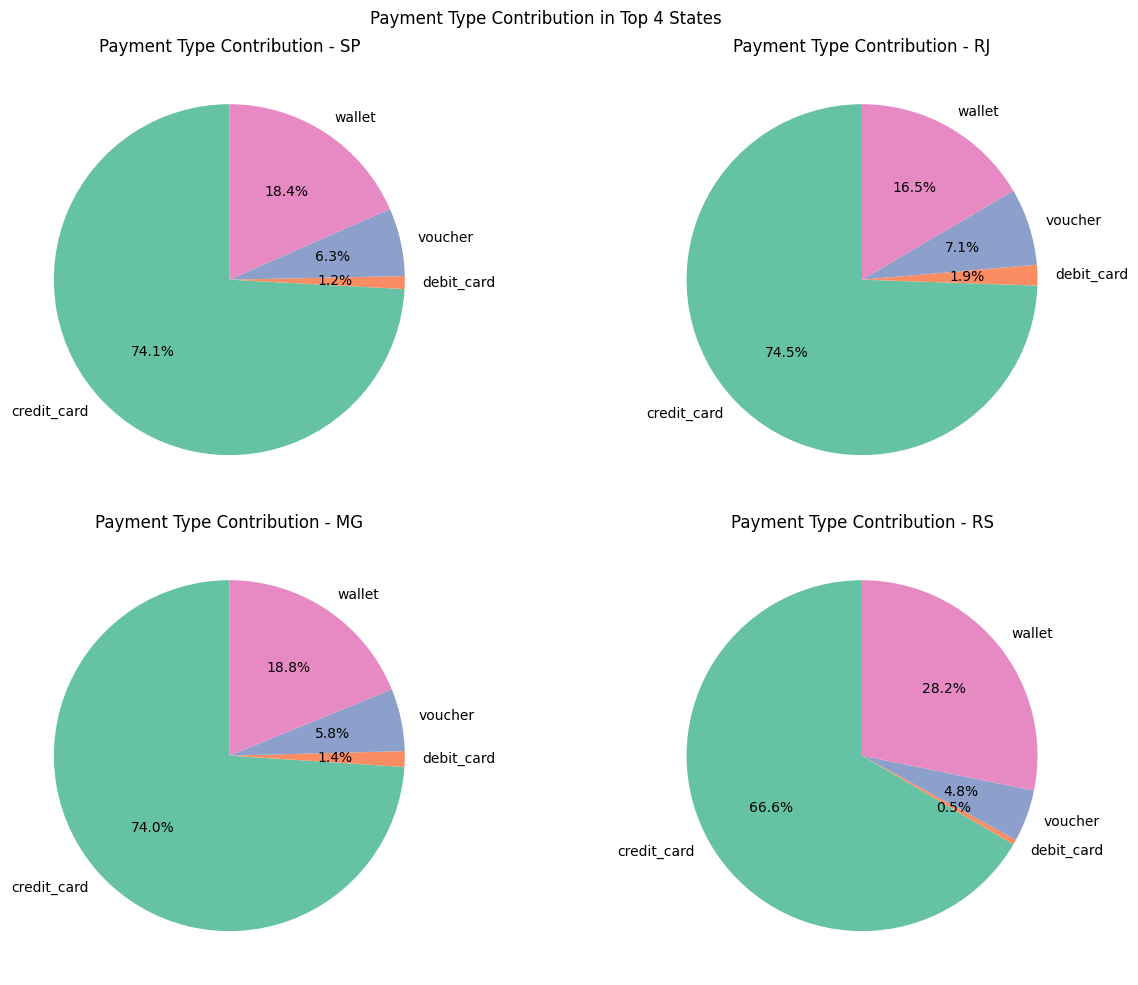

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.merge(orders, customers, on='customer_id')
df = pd.merge(df, payments, on='order_id')

state_totals = df.groupby('customer_state')['payment_value'].sum()

top_4_states = state_totals.nlargest(4).index

payment_types = sorted(df['payment_type'].dropna().unique())

colors = plt.cm.Set2.colors[:len(payment_types)]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for i, state in enumerate(top_4_states):
    ax = axes.flatten()[i]

    state_data = df[df['customer_state'] == state]

    result = state_data.groupby('payment_type')['payment_value'].sum()

    result = result.reindex(payment_types, fill_value=0)

    ax.pie(
        result,
        labels=payment_types,
        autopct='%1.1f%%',
        colors=colors,
        startangle=90
    )

    ax.set_title('Payment Type Contribution - ' + state)

plt.suptitle('Payment Type Contribution in Top 4 States')
plt.tight_layout()
plt.show()

Q-14

      month  median_delay  valid_order_count
0   2016-10     13.250833                113
1   2016-12      0.247222                  1
2   2017-01      0.434444                332
3   2017-02      0.228056                657
4   2017-03      0.000000               1058
5   2017-04      0.246250                908
6   2017-05      0.239444               1461
7   2017-06      0.261667               1238
8   2017-07      0.255972               1602
9   2017-08      0.319722               1753
10  2017-09      0.273611               1711
11  2017-10      0.313333               1890
12  2017-11      0.455833               2926
13  2017-12      0.368889               2115
14  2018-01      0.308333               2753
15  2018-02      0.382222               2680
16  2018-03      0.338333               2686
17  2018-04      0.465833               2636
18  2018-05      0.473889               2641
19  2018-06      0.449028               2356
20  2018-07      0.503889               2369
21  2018-0

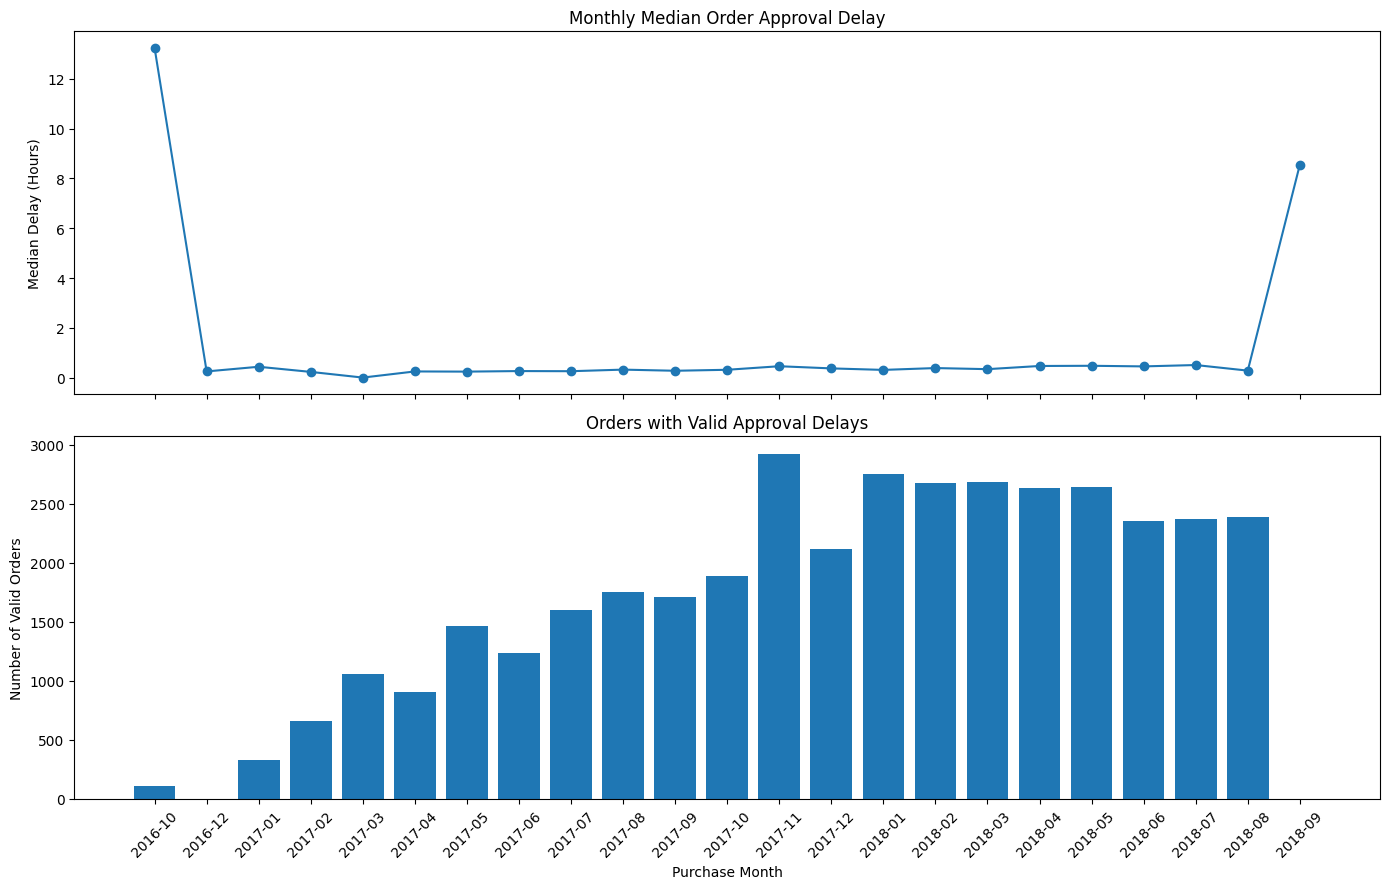

Note: Approval delay is the time between purchase and approval. It is not delivery time.


In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df = orders.copy()

df['order_purchase_timestamp'] = pd.to_datetime(
    df['order_purchase_timestamp']
)

df['order_approved_at'] = pd.to_datetime(
    df['order_approved_at']
)

df = df.dropna(subset=[
    'order_purchase_timestamp',
    'order_approved_at'
])

df['approval_delay_hours'] = (
    df['order_approved_at'] -
    df['order_purchase_timestamp']
).dt.total_seconds() / 3600

df = df[df['approval_delay_hours'] >= 0]

df['month'] = df['order_purchase_timestamp'].dt.to_period('M')

result = df.groupby('month').agg(
    median_delay=('approval_delay_hours', 'median'),
    valid_order_count=('order_id', 'nunique')
).reset_index()

print(result)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

axes[0].plot(
    result['month'].astype(str),
    result['median_delay'],
    marker='o'
)

axes[0].set_ylabel('Median Delay (Hours)')
axes[0].set_title('Monthly Median Order Approval Delay')

axes[1].bar(
    result['month'].astype(str),
    result['valid_order_count']
)

axes[1].set_xlabel('Purchase Month')
axes[1].set_ylabel('Number of Valid Orders')
axes[1].set_title('Orders with Valid Approval Delays')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Note: Approval delay is the time between purchase and approval. It is not delivery time.")

Q-15

              customer_city customer_state  distinct_orders  total_item_price
2519              sao paulo             SP             6160         2002615.0
2197         rio de janeiro             RJ             2730          918209.0
312          belo horizonte             MG             1086          379168.0
394                brasilia             DF              837          286364.0
2071           porto alegre             RS              577          231138.0
799                curitiba             PR              562          201513.0
1061              guarulhos             SP              483          197316.0
496                campinas             SP              555          194074.0
2264               salvador             BA              489          164152.0
2399  sao bernardo do campo             SP              359          129758.0


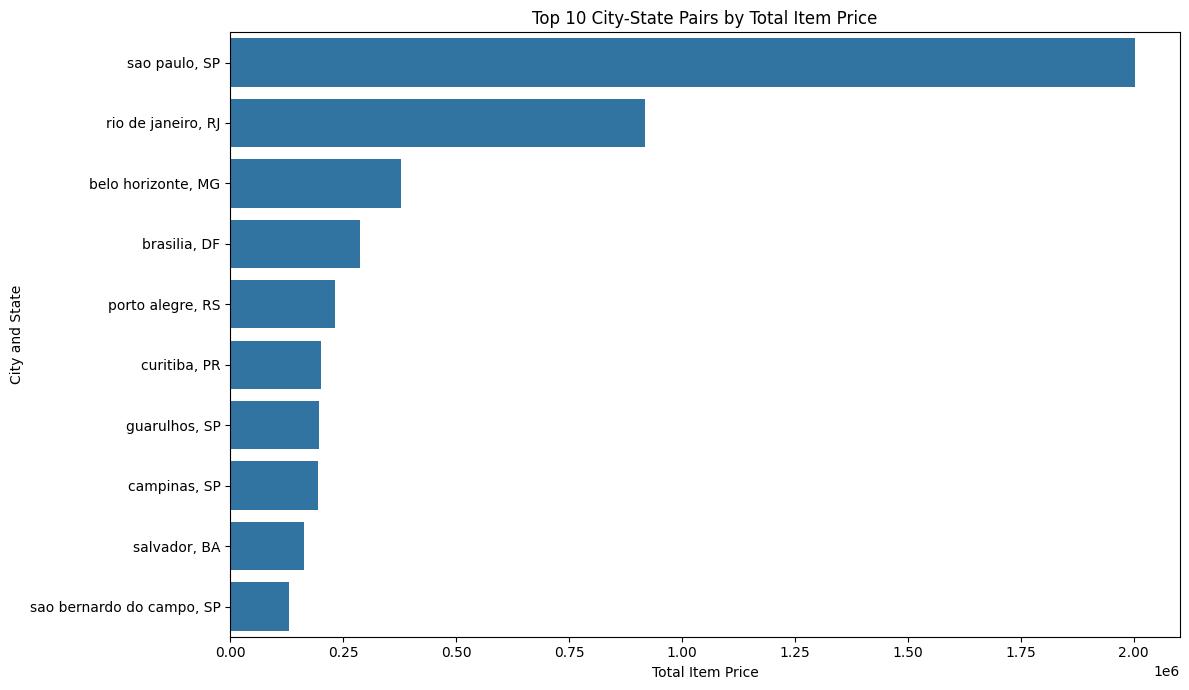

In [38]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.merge(order_items, orders, on='order_id')
df = pd.merge(df, customers, on='customer_id')

result = df.groupby(
    ['customer_city', 'customer_state']
).agg(
    distinct_orders=('order_id', 'nunique'),
    total_item_price=('price', 'sum')
).reset_index()

result = result[result['distinct_orders'] >= 30]

top_10 = result.nlargest(10, 'total_item_price').copy()

top_10['city_state'] = (
    top_10['customer_city'] + ', ' +
    top_10['customer_state']
)

print(top_10[
    ['customer_city', 'customer_state',
     'distinct_orders', 'total_item_price']
])

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10,
    x='total_item_price',
    y='city_state'
)

plt.xlabel('Total Item Price')
plt.ylabel('City and State')
plt.title('Top 10 City-State Pairs by Total Item Price')

plt.tight_layout()
plt.show()